# Mixing barium-rich formation waters: scale risk and practical solutions

**Version 1.0.0 · Synthetic teaching study · 16 October 2026**

Can two formation waters be produced through the same manifold and water-treatment system?
The central question is whether barium in one water encounters sulfate in the other. A low
sulfate concentration in the barium-rich sample does **not** establish compatibility after mixing.
This notebook develops the discussion, runs native NeqSim scale screens, calculates defensible
inventory limits, and turns the results into a treatment and test plan.

No field analysis was supplied. Waters A, B and C below are invented, charge-balanced examples,
not data from Equinor or any named field. Replace them with representative laboratory analyses.
Water B represents a sulfate-bearing formation/produced water, which could include injection-water
breakthrough; it is **not automatically seawater**. Water C represents another sulfate-poor formation water.

**Read this distinction throughout:** saturation index is a thermodynamic tendency; equilibrium
solid mass is a model result; deposited mass and time to blockage require kinetics and transport.
Neither a positive SI nor a large inventory limit specifies a deposition rate.

Companion: [Mineral-scale thermodynamics and flowline control](../thermodynamics/ThermodynamicsOfMineralScale.ipynb).

## 1. Why mixing creates a new problem

The principal reaction is

$$\mathrm{Ba^{2+}+SO_4^{2-}\rightleftharpoons BaSO_4(s)}$$

Barium-rich, sulfate-depleted waters can coexist in separate reservoirs. Commingling introduces
the missing counter-ion. Local mixing occurs at perforations, crossflow zones, subsea tees,
manifolds, separator water legs, produced-water headers and reinjection facilities. The first
mixing point matters: a chemical injected downstream cannot protect the upstream contact zone.

| Scale or deposit | What changes on mixing or production? | What to investigate |
|---|---|---|
| Barite, BaSO₄ | Ba meets sulfate; very low solubility | Full mixing envelope, dissolved Ba/SO₄ and inhibitor delivery |
| Celestite, SrSO₄ | Sr shares the sulfate inventory | Simultaneous solids; possible Ba/Sr solid solutions |
| CaSO₄ minerals | Ca, sulfate, temperature and water activity | Distinguish gypsum from anhydrite |
| Calcite, CaCO₃ | Alkalinity, pH and CO₂ loss change | Gas–water equilibrium during depressurization; never average pH |
| FeS / FeCO₃ / corrosion solids | H₂S, dissolved iron, oxygen and corrosion | Redox/speciation, oxygen exclusion and deposit analysis |

Salt precipitation can impair injectivity, restrict valves, foul heat exchangers and separators,
and overload filters. Some solids remain suspended and travel downstream. Barite may incorporate
radium when present: characterize NORM in real deposits before selecting handling/disposal.
These additional phenomena are discussed here but are not quantitatively simulated.

## 2. Definitions, units and model boundaries

For dimensionless activities on the 1 mol/kg-water standard state,

$$a_i=\gamma_i\frac{m_i}{m^\circ},\qquad SI=\log_{10}\left(\frac{a_{\mathrm{Ba^{2+}}}a_{\mathrm{SO_4^{2-}}}}{K_{sp}(T,P)}\right)$$

Here $m_i$ is free-ion molality, $m^\circ=1\ \mathrm{mol\,kg^{-1}}$, $\gamma_i$ is its activity
coefficient and $K_{sp}$ is the dimensionless thermodynamic solubility product. SI > 0 means
supersaturation; SI = 0 means saturation. SI < 0 applies only to the specified mineral and state.

The executable screen uses NeqSim `ScalePredictionCalculator` and
`MultiMineralScaleEquilibrium.ActivityModel.PITZER_BINARY`. The latter maps binary salt parameters
to trace-ion coefficients at equivalent ionic strength. It is **not full multicomponent Pitzer**.
The predictor supplies an approximate ion-paired free-ion pool, then the solids solver holds
activity coefficients and that pool's speciation assumptions fixed while sharing ions among solids.
Its precipitation balance covers the tracked free ions, not a re-equilibrated analytical inventory.

Concentrations are mg/L of water sample (ion mass, not salt mass); pressures are bara. The code
calculates ionic strength in mol/kg water from the assumed density and dissolved-solids mass.
However, the native solids screen still uses mol/L in its ion products. Supplying molal ionic
strength does not remove that standard-state approximation. A complete Pitzer/speciation model,
with density and equilibrium constants on a consistent basis, is required for quantitative design.

All blends assume additive sample volumes at a common reference state. Temperature/pressure
sensitivities retain that reference concentration basis; thermal expansion, flashing and gas loss
are not solved. pH = 6.5 is a specified scenario, not a pH mixing calculation.

## 3. Reproducible NeqSim runtime

The default Colab route builds the pinned master source below (the inspected master on the study
date). Java 17 and Maven are required; the cell installs them on Colab if absent. The Python
package is only the bridge. Start with a fresh runtime if a JVM has already been loaded.

For local validation, `NEQSIM_SOURCE_ROOT` and `NEQSIM_SOURCE_JAR` can reuse a source build.
An optional `NEQSIM_AUDITED_SOURCE_MANIFEST` validates a connector-reconstructed snapshot against
all 3,675 authoritative source/resource/POM hashes; otherwise git `rev-parse` verifies the checkout.
The notebook records the actual JAR hash and checks the loaded Java class location.

In [1]:
import hashlib
import importlib.metadata
import importlib.util
import json
import os
from pathlib import Path
import platform
import shutil
import subprocess
import sys

NEQSIM_SOURCE_REF = "54d6be9c794cec093fbfa0e347fa54f5250881db"
NEQSIM_REPOSITORY = "https://github.com/equinor/neqsim.git"

def command(arguments, cwd=None):
    result = subprocess.run(
        arguments, cwd=cwd, text=True, capture_output=True, check=True,
    )
    return result.stdout.strip()

for dependency in ["neqsim", "numpy", "pandas", "matplotlib"]:
    if importlib.util.find_spec(dependency) is None:
        command([sys.executable, "-m", "pip", "install", "-q", dependency])

source_root = Path(os.environ.get("NEQSIM_SOURCE_ROOT", "neqsim-source")).resolve()
jar_override = os.environ.get("NEQSIM_SOURCE_JAR")
if not jar_override:
    if shutil.which("java") is None or shutil.which("mvn") is None:
        command(["apt-get", "update", "-qq"])
        command(["apt-get", "install", "-y", "-qq", "openjdk-17-jdk", "maven"])
    if not (source_root / ".git").exists():
        command(["git", "clone", "--filter=blob:none", NEQSIM_REPOSITORY, str(source_root)])
    command(["git", "fetch", "origin", NEQSIM_SOURCE_REF], source_root)
    command(["git", "checkout", "--detach", NEQSIM_SOURCE_REF], source_root)
    command([
        "mvn", "-q", "-Dmaven.test.skip=true", "-Dmaven.javadoc.skip=true", "package",
    ], source_root)
    jars = [p for p in (source_root / "target").glob("neqsim-*.jar")
            if not any(tag in p.name for tag in ["sources", "javadoc", "shaded", "original"])]
    assert len(jars) == 1, jars
    jar_path = jars[0].resolve()
else:
    jar_path = Path(jar_override).resolve()

manifest_path = os.environ.get("NEQSIM_AUDITED_SOURCE_MANIFEST")
if manifest_path:
    manifest = json.loads(Path(manifest_path).read_text())
    source_commit = manifest["source_commit"]
    for entry in manifest["files"]:
        digest = hashlib.sha256((source_root / entry["path"]).read_bytes()).hexdigest()
        assert digest == entry["sha256"], entry["path"]
    print("Audited build input files:", len(manifest["files"]))
else:
    source_commit = command(["git", "rev-parse", "HEAD"], source_root)
    assert not command(["git", "status", "--porcelain", "--", "src/main", "pom.xml"], source_root)
assert source_commit == NEQSIM_SOURCE_REF
jar_sha256 = hashlib.sha256(jar_path.read_bytes()).hexdigest()

os.environ["NEQSIM_JVM_AUTOSTART"] = "0"
import jpype

assert not jpype.isJVMStarted(), "Restart the runtime before changing the Java JAR."
jpype.addClassPath(str(jar_path))
jpype.startJVM(convertStrings=True)
Predictor = jpype.JClass("neqsim.pvtsimulation.flowassurance.ScalePredictionCalculator")
Equilibrium = jpype.JClass("neqsim.pvtsimulation.flowassurance.MultiMineralScaleEquilibrium")
origin = str(Equilibrium.class_.getProtectionDomain().getCodeSource().getLocation())
assert Path(origin.removeprefix("file:")).resolve() == jar_path
provenance = {
    "source_commit": source_commit,
    "jar_sha256": jar_sha256,
    "class_origin": origin,
    "python": platform.python_version(),
    "java": str(jpype.JClass("java.lang.System").getProperty("java.version")),
    "packages": {name: importlib.metadata.version(name)
                 for name in ["neqsim", "JPype1", "numpy", "pandas", "matplotlib"]},
}
print(json.dumps(provenance, indent=2))

Audited build input files: 3675
{
  "source_commit": "54d6be9c794cec093fbfa0e347fa54f5250881db",
  "jar_sha256": "806fb3404843a12d29fb7d559d953895493c7d9f3cdfacdc2d27dacfe95bafc6",
  "class_origin": "file:/workspace/scratch/75b0f1c110d8/neqsim-source/target/neqsim-3.25.0.jar",
  "python": "3.12.14",
  "java": "17.0.20",
  "packages": {
    "neqsim": "3.24.0",
    "JPype1": "1.7.1",
    "numpy": "2.3.5",
    "pandas": "2.2.3",
    "matplotlib": "3.10.8"
  }
}


## 4. Three synthetic waters and analytical quality checks

All ions except chloride are explicit assumptions. Chloride is **constructed** to make these
synthetic recipes electrically neutral; do not silently balance real laboratory data this way.
Report an analytical charge imbalance and investigate missing ions, alkalinity conventions,
sampling precipitation and units. Dissolved and total-metal measurements must be distinguished.

The input table is intentionally editable. Density is kg/L of solution at the sample reference
state. TDS is the sum of listed ion masses. Ion molar masses are g/mol, numerically mg/mmol.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 130, "font.size": 10, "axes.spines.top": False})
MW = {"Na": 22.98977, "K": 39.0983, "Ca": 40.078, "Mg": 24.305,
      "Ba": 137.327, "Sr": 87.62, "Cl": 35.453, "SO4": 96.06, "HCO3": 61.0168}
Z = {"Na": 1, "K": 1, "Ca": 2, "Mg": 2, "Ba": 2,
     "Sr": 2, "Cl": -1, "SO4": -2, "HCO3": -1}
BARITE_MW = 233.39

def balance_chloride(recipe):
    water = dict(recipe)
    charge_without_cl = sum(water[ion] / MW[ion] * Z[ion]
                            for ion in MW if ion != "Cl")
    water["Cl"] = charge_without_cl * MW["Cl"]
    assert water["Cl"] >= 0.0
    return water

water_a = balance_chloride({
    "Na": 23000., "K": 200., "Ca": 500., "Mg": 100., "Ba": 800.,
    "Sr": 100., "SO4": 0.01, "HCO3": 500., "density": 1.06,
})
water_b = balance_chloride({
    "Na": 18000., "K": 150., "Ca": 300., "Mg": 100., "Ba": 0.02,
    "Sr": 5., "SO4": 1200., "HCO3": 300., "density": 1.045,
})
water_c = balance_chloride({
    "Na": 20000., "K": 200., "Ca": 600., "Mg": 100., "Ba": 20.,
    "Sr": 30., "SO4": 0.05, "HCO3": 700., "density": 1.05,
})
waters = {"A: Ba rich": water_a, "B: sulfate bearing": water_b, "C: sulfate poor": water_c}

def chemistry_metrics(water):
    tds = sum(water[ion] for ion in MW)
    solvent_kg_l = water["density"] - tds / 1e6
    assert solvent_kg_l > 0.0
    equivalents = {ion: water[ion] / (1000.0 * MW[ion]) * Z[ion] for ion in MW}
    cations = sum(value for value in equivalents.values() if value > 0.0)
    anions = -sum(value for value in equivalents.values() if value < 0.0)
    imbalance = 100.0 * (cations - anions) / (cations + anions)
    strength = 0.5 * sum(water[ion] / (1000.0 * MW[ion]) * Z[ion] ** 2 for ion in MW)
    return {"TDS [mg/L]": tds, "water [kg/L]": solvent_kg_l,
            "I [mol/kg water]": strength / solvent_kg_l,
            "charge imbalance [%]": imbalance}

input_table = pd.DataFrame(waters).loc[list(MW)].round(3)
input_table.index.name = "Ion [mg/L]"
display(input_table)
display(pd.DataFrame({name: chemistry_metrics(water) for name, water in waters.items()}).T)

,A: Ba rich,B: sulfate bearing,C: sulfate poor
Ion [mg/L],,,
Na,23000.000,18000.000,20000.000
K,200.000,150.000,200.000
Ca,500.000,300.000,600.000
Mg,100.000,100.000,100.000
Ba,800.000,0.020,20.000
Sr,100.000,5.000,30.000
Cl,37029.926,27660.656,32004.863
SO4,0.010,1200.000,0.050
HCO3,500.000,300.000,700.000


,TDS [mg/L],water [kg/L],I [mol/kg water],charge imbalance [%]
A: Ba rich,62229.935714,0.997770,1.078636,-1.054669e-14
B: sulfate bearing,47715.675680,0.997284,0.836528,0.000000e+00
C: sulfate poor,53654.912553,0.996345,0.937213,-6.072009e-15


## 5. Mix conservatively, then evaluate scale

For the fraction $f$ of sample volume from A, the pre-precipitation concentration is

$$C_i(f)=fC_{i,A}+(1-f)C_{i,B}$$

Concentrations $C_i$ are mg/L. A field calculation should mix component molar/mass flow rates
and calculate the mixed volume, temperature and gas–water equilibrium. pH must follow alkalinity,
gas exchange and reactions; it is not volume averaged.

We sweep the whole envelope. A nominal 50:50 blend can miss the highest SI or largest possible
solid mass. Local mixing fronts can also pass through more aggressive compositions than the
bulk outlet. Reuse `screen()` for laboratory analyses after reviewing its stated limitations.

In [3]:
MINERALS = ["BaSO4", "SrSO4", "CaSO4", "CaCO3"]

def mix(water_left, water_right, fraction_a):
    assert 0.0 <= fraction_a <= 1.0
    return {key: fraction_a * water_left[key] + (1.0 - fraction_a) * water_right[key]
            for key in water_left}

def screen(water, temperature_c=60.0, pressure_bara=50.0, ph=6.5):
    metrics = chemistry_metrics(water)
    predictor = Predictor()
    predictor.setTemperatureCelsius(temperature_c)
    predictor.setPressureBara(pressure_bara)
    predictor.setPH(ph)
    predictor.setCalciumConcentration(water["Ca"])
    predictor.setBariumConcentration(water["Ba"])
    predictor.setStrontiumConcentration(water["Sr"])
    predictor.setMagnesiumConcentration(water["Mg"])
    predictor.setSodiumConcentration(water["Na"])
    predictor.setSulphateConcentration(water["SO4"])
    predictor.setBicarbonateConcentration(water["HCO3"])
    predictor.setIronConcentration(0.0)
    predictor.setTotalDissolvedSolids(metrics["TDS [mg/L]"])
    equilibrium = Equilibrium(predictor)
    equilibrium.setActivityModel(Equilibrium.ActivityModel.PITZER_BINARY)
    equilibrium.setPitzerIonicStrengthMolal(metrics["I [mol/kg water]"])
    equilibrium.setSolverControls(10000, 1.0, 1e-15)
    equilibrium.solve()
    residual = float(equilibrium.getMaximumComplementarityViolation())
    balance = float(equilibrium.getMaximumIonBalanceResidualMolPerL())
    assert np.isfinite(residual) and residual <= 1e-3, residual
    assert balance <= 1e-12, balance
    assert not equilibrium.hasReachedIterationLimit()
    row = {"complementarity [SI]": residual, "free-ion balance [mol/L]": balance}
    for mineral in MINERALS:
        result = equilibrium.getResults().get(mineral)
        assert result is not None, mineral
        row[mineral + " initial SI"] = float(result.getInitialSI())
        row[mineral + " final SI"] = float(result.getFinalSI())
        row[mineral + " screen [mg/L]"] = float(result.getPrecipitatedMassMgPerL())
    inventory_bound = BARITE_MW * min(water["Ba"] / MW["Ba"], water["SO4"] / MW["SO4"])
    row["BaSO4 inventory bound [mg/L]"] = inventory_bound
    assert -1e-10 <= row["BaSO4 screen [mg/L]"] <= inventory_bound + 1e-6
    return row, predictor, equilibrium

def sweep(water_right, points=101, **conditions):
    records = []
    for fraction in np.linspace(0.0, 1.0, points):
        row, _, _ = screen(mix(water_a, water_right, fraction), **conditions)
        records.append({"fraction A": fraction, **row})
    return pd.DataFrame(records)

ab = sweep(water_b)
ac = sweep(water_c)
selected = ["fraction A", "BaSO4 initial SI", "BaSO4 screen [mg/L]",
            "BaSO4 inventory bound [mg/L]", "SrSO4 initial SI", "CaCO3 initial SI"]
display(ab.loc[[0, 10, 25, 50, 75, 90, 100], selected].round(5))
summary = []
for label, table in {"A + B": ab, "A + C": ac}.items():
    peak_si = table.loc[table["BaSO4 initial SI"].idxmax()]
    peak_mass = table.loc[table["BaSO4 screen [mg/L]"].idxmax()]
    summary.append({"mixture": label, "max barite SI": peak_si["BaSO4 initial SI"],
                    "fraction A at max SI": peak_si["fraction A"],
                    "max screened barite [mg/L]": peak_mass["BaSO4 screen [mg/L]"],
                    "fraction A at max mass": peak_mass["fraction A"]})
display(pd.DataFrame(summary).round(5))

,fraction A,BaSO4 initial SI,BaSO4 screen [mg/L],BaSO4 inventory bound [mg/L],SrSO4 initial SI,CaCO3 initial SI
0,0.00,-1.36975,0.00000,0.03399,-3.29146,-1.39430
10,0.10,2.14813,134.90988,135.99220,-2.91332,-1.39297
25,0.25,2.40663,337.87718,339.92952,-2.75538,-1.40443
50,0.50,2.42425,532.94057,679.82504,-2.77717,-1.45594
75,0.75,2.18244,221.22791,728.90642,-3.03288,-1.54199
90,0.90,1.78862,76.98557,291.57714,-3.43138,-1.60724
100,1.00,-2.29708,0.00000,0.02430,-7.51941,-1.65550


,mixture,max barite SI,fraction A at max SI,max screened barite [mg/L],fraction A at max mass
0,A + B,2.45113,0.38,578.01486,0.45
1,A + C,-1.97280,0.49,0.00000,0.00


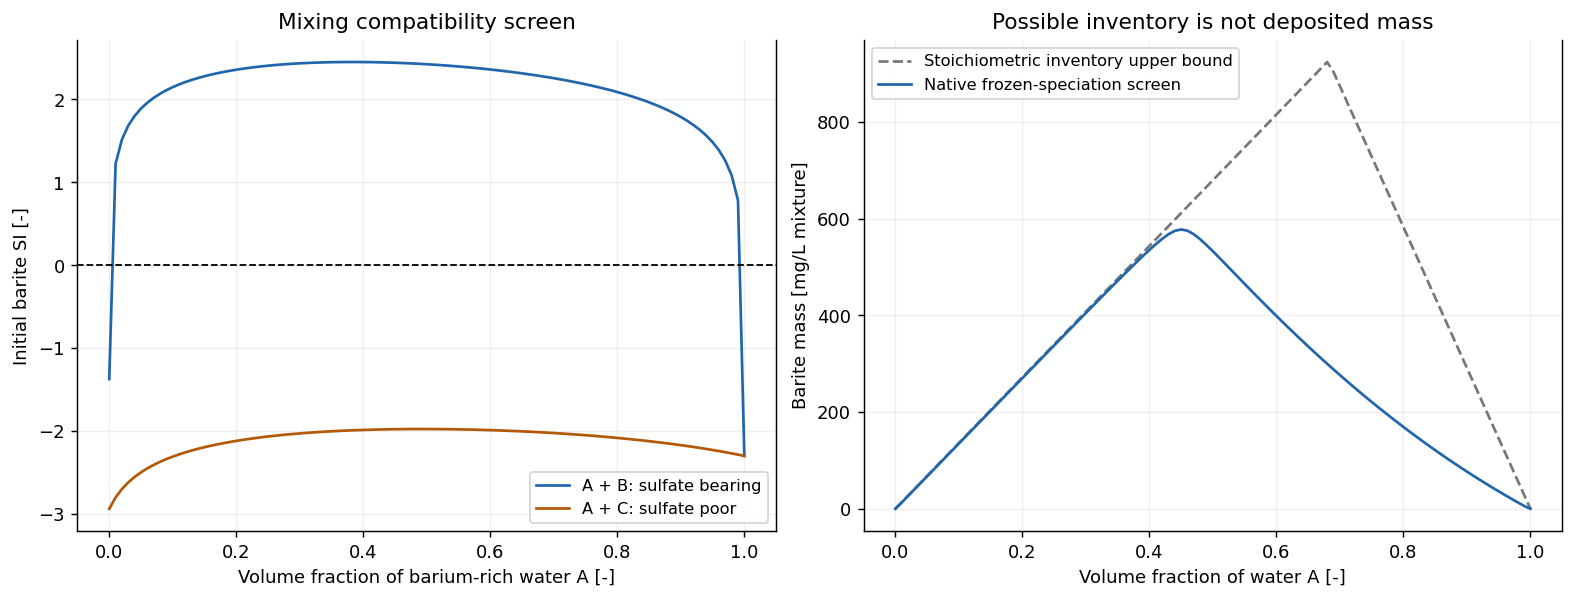

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for label, table, color in [("A + B: sulfate bearing", ab, "#2166ac"),
                            ("A + C: sulfate poor", ac, "#b35806")]:
    axes[0].plot(table["fraction A"], table["BaSO4 initial SI"], label=label, color=color)
axes[0].axhline(0.0, color="black", linestyle="--", linewidth=1)
axes[0].set(xlabel="Volume fraction of barium-rich water A [-]",
            ylabel="Initial barite SI [-]", title="Mixing compatibility screen")
axes[0].legend(fontsize=9)
axes[1].plot(ab["fraction A"], ab["BaSO4 inventory bound [mg/L]"],
             color="#777777", linestyle="--", label="Stoichiometric inventory upper bound")
axes[1].plot(ab["fraction A"], ab["BaSO4 screen [mg/L]"],
             color="#2166ac", label="Native frozen-speciation screen")
axes[1].set(xlabel="Volume fraction of water A [-]", ylabel="Barite mass [mg/L mixture]",
            title="Possible inventory is not deposited mass")
axes[1].legend(fontsize=9)
for axis in axes:
    axis.grid(alpha=0.2)
plt.show()

## 6. How much solid could the ion inventory supply?

The absolute stoichiometric upper bound (all available limiting ion becomes pure barite) is

$$C_{\mathrm{BaSO_4,max}}=M_{\mathrm{BaSO_4}}\min\left(\frac{C_{\mathrm{Ba}}}{M_{\mathrm{Ba}}},\frac{C_{\mathrm{SO_4}}}{M_{\mathrm{SO_4}}}\right)$$

$M$ values are g/mol and $C$ values are mg/L, so the result is mg/L. This bound ignores solubility,
competition and kinetics. It is neither a predicted equilibrium mass nor a lower bound on deposition.
The native screen can be much lower because its available free-sulfate pool is reduced by its
approximate pairing calculation and is not replenished by re-speciation during precipitation.
That discrepancy is a model limitation, not evidence that the remaining analytical sulfate is harmless.

At a water rate $Q_w$ in m³/day, the corresponding solids load in kg/day is

$$\dot m_{\mathrm{solid}}=\frac{C_{\mathrm{solid}}Q_w}{1000}$$

A water rate of 1,000 m³/day below is an illustrative rate at the same reference volume basis.
No fraction is assigned to wall deposition. Reservoir or injectivity damage also depends on
where small masses accumulate, not only on the total daily mass.

In [5]:
water_rate_m3_day = 1000.0
baseline_water = mix(water_a, water_b, 0.5)
baseline, baseline_predictor, baseline_equilibrium = screen(baseline_water)
load_table = pd.DataFrame([
    {"quantity": "Native frozen-speciation barite screen",
     "mg/L": baseline["BaSO4 screen [mg/L]"]},
    {"quantity": "Absolute barite inventory upper bound",
     "mg/L": baseline["BaSO4 inventory bound [mg/L]"]},
])
load_table["kg/day at stated water rate"] = load_table["mg/L"] * water_rate_m3_day / 1000.0
display(load_table.round(4))
display(pd.DataFrame([
    {"mineral": mineral, "initial SI": baseline[mineral + " initial SI"],
     "final SI": baseline[mineral + " final SI"],
     "screened solid [mg/L]": baseline[mineral + " screen [mg/L]"]}
    for mineral in MINERALS
]).round(6))
print("Baseline free sulfate / analytical sulfate:", round(
    baseline_predictor.getFreeSulphateMolPerL()
    / (baseline_water["SO4"] / (1000.0 * MW["SO4"])), 5,
))

Baseline free sulfate / analytical sulfate: 0.37206


,quantity,mg/L,kg/day at stated water rate
0,Native frozen-speciation barite screen,532.9406,532.9406
1,Absolute barite inventory upper bound,679.8250,679.8250


,mineral,initial SI,final SI,screened solid [mg/L]
0,BaSO4,2.424249,-0.000000,532.94057
1,SrSO4,-2.777173,-4.536001,0.00000
2,CaSO4,-1.958376,-3.717204,0.00000
3,CaCO3,-1.455939,-1.455939,0.00000


## 7. Temperature, pressure, pH and analytical uncertainty

Repeat the envelope over the conditions where mixing actually occurs. The next table varies
temperature and pressure independently, then examines a pH scenario and ±20% input perturbations.
These are sensitivity cases, not confidence intervals. The state range does not imply independent
experimental validation of every correlation. A later flash/CO₂-loss study must solve pH and
alkalinity consistently, especially for carbonate scale.

In [6]:
condition_rows = []
for temperature in [25., 60., 90.]:
    for pressure in [1.01325, 50., 150.]:
        table = sweep(water_b, points=51, temperature_c=temperature, pressure_bara=pressure)
        peak = table.loc[table["BaSO4 initial SI"].idxmax()]
        condition_rows.append({"T [C]": temperature, "P [bara]": pressure,
                               "max barite SI": peak["BaSO4 initial SI"],
                               "fraction A at max SI": peak["fraction A"],
                               "max screen [mg/L]": table["BaSO4 screen [mg/L]"].max()})
display(pd.DataFrame(condition_rows).round(4))

ph_rows = []
for ph in [5.5, 6.5, 7.5, 8.5]:
    row, _, _ = screen(baseline_water, ph=ph)
    ph_rows.append({"specified pH": ph, "barite SI": row["BaSO4 initial SI"],
                    "calcite SI": row["CaCO3 initial SI"]})
display(pd.DataFrame(ph_rows).round(5))

uncertainty_rows = []
for ba_factor in [0.8, 1.0, 1.2]:
    for sulfate_factor in [0.8, 1.0, 1.2]:
        changed = dict(baseline_water)
        changed["Ba"] *= ba_factor
        changed["SO4"] *= sulfate_factor
        changed = balance_chloride(changed)
        row, _, _ = screen(changed)
        uncertainty_rows.append({"Ba factor": ba_factor, "SO4 factor": sulfate_factor,
                                 "barite SI": row["BaSO4 initial SI"],
                                 "screen [mg/L]": row["BaSO4 screen [mg/L]"]})
display(pd.DataFrame(uncertainty_rows).round(5))

,T [C],P [bara],max barite SI,fraction A at max SI,max screen [mg/L]
0,25.0,1.0132,2.9701,0.40,603.1899
1,25.0,50.0000,2.9303,0.40,602.2249
2,25.0,150.0000,2.8490,0.40,600.1116
3,60.0,1.0132,2.4868,0.38,576.8775
4,60.0,50.0000,2.4511,0.38,575.4559
5,60.0,150.0000,2.3784,0.38,572.3502
6,90.0,1.0132,2.2976,0.38,568.4889
7,90.0,50.0000,2.2649,0.38,566.9152
8,90.0,150.0000,2.1982,0.38,563.4873


,specified pH,barite SI,calcite SI
0,5.5,2.42425,-2.45593
1,6.5,2.42425,-1.45594
2,7.5,2.42428,-0.45607
3,8.5,2.42456,0.54266


,Ba factor,SO4 factor,barite SI,screen [mg/L]
0,0.8,0.8,2.23408,424.28425
1,0.8,1.0,2.33035,507.15671
2,0.8,1.2,2.40890,532.44441
3,1.0,0.8,2.32797,428.33287
4,1.0,1.0,2.42425,532.94057
5,1.0,1.2,2.50280,625.41504
6,1.2,0.8,2.40412,428.25558
7,1.2,1.0,2.50041,534.93844
8,1.2,1.2,2.57897,640.04792


## 8. Can sulfate reduction or blending solve it?

Sulfate removal addresses the reaction inventory. The next calculation substitutes lower sulfate
levels in water B while retaining the other assumed ions and adjusting chloride for electroneutrality.
It is a **hypothetical feed specification**, not a membrane design: real nanofiltration alters
multiple ions, has rejection/recovery limits and requires pretreatment, concentrate disposal,
fouling control and suitable pressure/temperature. Treating produced brine is different from
treating clean seawater before injection.

We check all mixing fractions for each specification. An average sulfate target or outlet SI
does not establish safety at local mixing fronts. No safe sulfate limit or mixing ratio is
declared from this unqualified screen alone.

,B sulfate [mg/L],max barite SI,fraction A at max SI,max screen [mg/L],max inventory bound [mg/L]
0,1200.00,2.45113,0.38,578.01486,924.54982
1,120.00,1.45505,0.38,104.07644,239.07970
2,12.00,0.45564,0.38,5.94077,28.28159
3,1.20,-0.54233,0.38,0.00000,2.88664
4,0.12,-1.52185,0.40,0.00000,0.28888


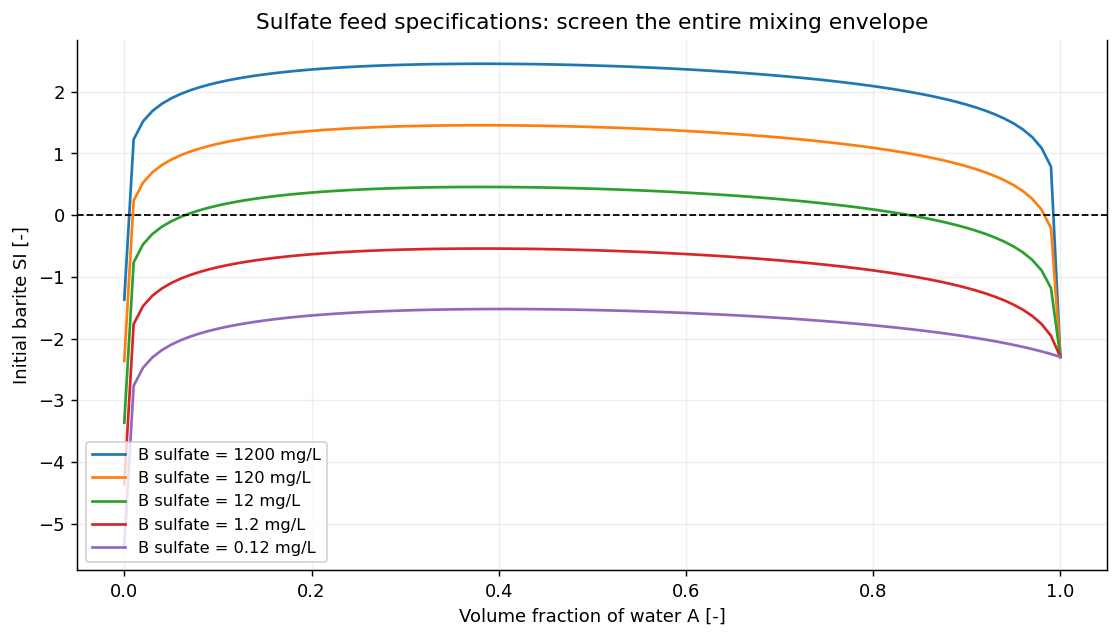

In [7]:
treatment_rows = []
treated_curves = {}
for sulfate_mg_l in [1200., 120., 12., 1.2, 0.12]:
    treated = dict(water_b)
    treated["SO4"] = sulfate_mg_l
    treated = balance_chloride(treated)
    curve = sweep(treated)
    treated_curves[sulfate_mg_l] = curve
    peak = curve.loc[curve["BaSO4 initial SI"].idxmax()]
    treatment_rows.append({"B sulfate [mg/L]": sulfate_mg_l,
                           "max barite SI": peak["BaSO4 initial SI"],
                           "fraction A at max SI": peak["fraction A"],
                           "max screen [mg/L]": curve["BaSO4 screen [mg/L]"].max(),
                           "max inventory bound [mg/L]":
                           curve["BaSO4 inventory bound [mg/L]"].max()})
treatment_table = pd.DataFrame(treatment_rows)
display(treatment_table.round(5))
fig, axis = plt.subplots(figsize=(8.5, 4.8), layout="constrained")
for sulfate, table in treated_curves.items():
    axis.plot(table["fraction A"], table["BaSO4 initial SI"],
              label=f"B sulfate = {sulfate:g} mg/L")
axis.axhline(0., color="black", linestyle="--", linewidth=1)
axis.set(xlabel="Volume fraction of water A [-]", ylabel="Initial barite SI [-]",
         title="Sulfate feed specifications: screen the entire mixing envelope")
axis.legend(fontsize=9, loc="lower left")
axis.grid(alpha=0.2)
plt.show()

## 9. Practical choices and their trade-offs

| Option | What it can achieve | Main challenges and evidence required |
|---|---|---|
| Keep waters separate | Avoid the incompatible contact upstream | Separate lines/water systems, crossflow prevention, cost and downstream/reinjection compatibility |
| Remove sulfate before contact | Reduce barite/SrSO₄ inventory | Qualify actual feed, rejection, recovery, fouling and concentrate disposal; assess all ions |
| Remove Ba in controlled treatment | Precipitate into an accessible vessel with solids separation | Reagent dose, nucleation/seeding, carryover, waste/NORM and residual chemistry; do not simply add sulfate to a live production line |
| Inject a qualified inhibitor before first contact | Delay nucleation/growth and attachment | Correct product, minimum effective concentration, mixing/contact time, high-Ca compatibility, temperature and residual monitoring |
| Limit or sequence commingling | Reduce exposure or stay inside a qualified operating envelope | Transient/local mixing can cross the worst ratio; lower rate may increase residence time; preserve production/injection objectives |
| Shift mixing to an accessible location | Improve chemical delivery, inspection and removal | May move the problem into produced-water treatment or reinjection rather than eliminate it |
| Planned removal | Restore capacity after deposition | Barite is difficult to remove with ordinary acid; qualify chelant/specialist dissolver or mechanical method on actual deposits |

**Inhibitors do not normally make SI negative.** A threshold inhibitor acts primarily on
nucleation/crystal growth/attachment. Do not subtract an arbitrary inhibition efficiency from
thermodynamic SI or infer a minimum dose from SI alone. High calcium can cause inhibitor
incompatibility/precipitation; verify compatibility with corrosion inhibitors, demulsifiers,
MEG/methanol and scavengers actually used. No inhibitor dose recommendation is made here.

Acid/pH control can mitigate carbonate scale but is not a general solution to barite.
Changing temperature, pressure or mixing intensity can relocate risk and affect kinetics; it does
not remove the Ba/SO₄ inventory. Turbulence can improve inhibitor distribution while also enhancing
mass transfer. Evaluate the complete process, including start-up, shut-in, backflow and water-cut changes.

## 10. Validate the calculation before interpreting the engineering

For a single barite solid and fixed free-ion activity product, the independent root satisfies

$$x=\frac{2(ab-K_c)}{a+b+\sqrt{(a-b)^2+4K_c}}$$

Here $a$ and $b$ are the initial free Ba and sulfate concentrations (mol/L), $x$ is precipitated
barite (mol/L), and $K_c$ is the effective concentration-product threshold ((mol/L)²) used by this
screen. If $ab\le K_c$, set $x=0$. This stable quadratic root checks the numerical precipitation
solver; it does not independently validate the activity/ion-pairing model or Ksp.

We also check charge balance, limiting-ion mass bounds, complementarity, repeated execution and
mixing-grid refinement. These tests can establish internally consistent screening results, not
agreement with a laboratory precipitation experiment.

In [8]:
ba_free = float(baseline_predictor.getTotalBariumMolPerL())
so4_free = float(baseline_predictor.getFreeSulphateMolPerL())
barite_result = baseline_equilibrium.getResults().get("BaSO4")
k_concentration = float(baseline_predictor.getKspBarite()) / float(
    barite_result.getActivityCoefficientProduct()
)
extent = max(0.0, 2.0 * (ba_free * so4_free - k_concentration) / (
    ba_free + so4_free + np.sqrt((ba_free - so4_free) ** 2 + 4.0 * k_concentration)
))
analytical_mass = extent * BARITE_MW * 1000.0
native_mass = baseline["BaSO4 screen [mg/L]"]
assert all(baseline[mineral + " screen [mg/L]"] == 0.0
           for mineral in MINERALS if mineral != "BaSO4")
assert np.isclose(analytical_mass, native_mass, rtol=1e-6, atol=1e-7)
repeat, _, _ = screen(baseline_water)
assert np.isclose(repeat["BaSO4 initial SI"], baseline["BaSO4 initial SI"], atol=1e-12)
refined = sweep(water_b, points=401)
grid_si_change = abs(refined["BaSO4 initial SI"].max() - ab["BaSO4 initial SI"].max())
assert grid_si_change < 1e-3
assert all(abs(chemistry_metrics(water)["charge imbalance [%]"]) < 1e-10
           for water in waters.values())
assert ab["BaSO4 initial SI"].max() > 0.0
assert ac["BaSO4 initial SI"].max() < 0.0
assert 0.0 < ab.loc[ab["BaSO4 initial SI"].idxmax(), "fraction A"] < 1.0
print("PASS: charge balance, all-case solid bounds and free-ion complementarity/balance.")
print("PASS: repeatability, internal maximum and sulfate-poor control.")
print(f"Independent barite root: {analytical_mass:.8f} mg/L; native: {native_mass:.8f} mg/L")
print(f"101-to-401-point change in maximum SI: {grid_si_change:.8g}")
print("Experimental high-salinity mixture validation: NOT ESTABLISHED by these checks.")

PASS: charge balance, all-case solid bounds and free-ion complementarity/balance.
PASS: repeatability, internal maximum and sulfate-poor control.
Independent barite root: 532.94056964 mg/L; native: 532.94056964 mg/L
101-to-401-point change in maximum SI: 1.804929e-05
Experimental high-salinity mixture validation: NOT ESTABLISHED by these checks.


## 11. Full Pitzer support: an explicit qualification boundary

The current full `SystemPitzer` path rejects the minimal Na–Ba–Cl–SO₄ example below because its
active interaction topology is incomplete. The code catches **only that known coverage failure**;
unrelated failures stop execution. No legacy parameter opt-out is used. This diagnostic is kept
separate from the accepted screening results.

The capability gap is tracked in [equinor/neqsim#4351](https://github.com/equinor/neqsim/issues/4351),
under the [electrolyte campaign #3144](https://github.com/equinor/neqsim/issues/3144).
Full Pitzer output must not be invented or inferred from the binary screen. Qualification needs
traceable parameters, independent barite solubility/mixed-brine data, consistent molality/speciation,
and dissolved-plus-solid elemental balances. Ba/Sr solid solutions, radium partitioning and
deposit kinetics require additional models/data.

In [9]:
SystemPitzer = jpype.JClass("neqsim.thermo.system.SystemPitzer")
Operations = jpype.JClass("neqsim.thermodynamicoperations.ThermodynamicOperations")
qualification_fluid = SystemPitzer(298.15, 1.01325)
for component, amount in {"water": 55.508, "Na+": 1.0, "Ba++": 0.001,
                          "Cl-": 1.0, "SO4--": 0.001}.items():
    qualification_fluid.addComponent(component, amount)
qualification_fluid.setMixingRule("classic")
qualification_fluid.init(0)
try:
    full_result = Operations(qualification_fluid).precipitateScale("BaSO4")
except jpype.JException as error:
    detail = str(error.stacktrace())
    if "Pitzer parameter coverage incomplete" not in detail:
        raise
    cause = next(line for line in detail.splitlines()
                 if "Pitzer parameter coverage incomplete" in line)
    print("Full-Pitzer qualification: BLOCKED by known parameter coverage (#4351).")
    print(cause)
else:
    print("Full-Pitzer coverage now executes; independent accuracy qualification still required.")
    print("Diagnostic precipitated mass [g]:", full_result.getPrecipitatedMassGrams())

Full-Pitzer qualification: BLOCKED by known parameter coverage (#4351).
Caused by: java.lang.IllegalStateException: Pitzer parameter coverage incomplete for dataset 'neqsim-legacy-pitzer-parameters-v1': activeCations=[Ba++, Na+], activeAnions=[Cl-, SO4--], missingBinary=[], missingTheta=[Ba++|Na+, Cl-|SO4--], missingPsi=[Ba++|Na+|Cl-, Ba++|Na+|SO4--, Cl-|SO4--|Ba++, Cl-|SO4--|Na+]


## 12. A field qualification and operating plan

1. **Collect representative analyses:** dissolved/total Ba, Sr, Ca, Mg, Na, K, Cl, sulfate,
   alkalinity, density, TDS, in-situ pH, dissolved CO₂/H₂S and iron. Include sampling state,
   filtration/preservation, analytical uncertainty and detection limits. Investigate charge balance.
2. **Map contact points:** reservoir crossflow, well completion, subsea manifold, topsides and
   reinjection. Obtain each water rate versus time, temperature/pressure paths and chemical
   injection locations. Include startup slugs, backflow and changing injection-water breakthrough.
3. **Qualify thermodynamics:** run the whole mixing envelope with a suitable fully specified
   high-salinity model (for example independently qualified PHREEQC Pitzer), correct gas–water
   boundary conditions and simultaneous minerals. Benchmark against relevant measured solubility.
4. **Measure kinetics and treatment:** static compatibility bottles for induction/precipitation,
   dynamic tube-blocking/deposition tests at representative flow and temperature, and inhibitor
   residual/compatibility measurements. Include the worst predicted ratios and untreated controls.
   A clear bottle for a short time does not establish long-term protection.
5. **Select and monitor an operating envelope:** minimum qualified chemical residual before first
   contact, acceptable blend/rate states, filter differential pressure, valve response, coupons,
   dissolved-ion depletion and solids samples. Use XRD/SEM or suitable mineral analysis to identify
   deposits. Define responses to loss of chemical injection and unexpected water composition.

**Discussion questions.** Would separate production lines merely postpone mixing until the
separator? Can an inhibitor reach the first contact point during startup? Does a higher flow rate
reduce residence time but increase solids throughput? Can treatment solids be reliably removed
before reinjection? Which measured observation would distinguish barite from corrosion products?

In [10]:
peak = ab.loc[ab["BaSO4 initial SI"].idxmax()]
print("RESULTS FOR THE SYNTHETIC INPUTS")
print(f"A+B maximum screened barite SI = {peak['BaSO4 initial SI']:.3f}")
print(f"Volume fraction A at that maximum = {peak['fraction A']:.3f}")
print(f"50:50 native barite screen = {native_mass:.3f} mg/L")
print(f"50:50 barite inventory upper bound = {baseline['BaSO4 inventory bound [mg/L]']:.3f} mg/L")
print(f"A+C maximum screened barite SI = {ac['BaSO4 initial SI'].max():.3f}")
print("A+B requires treatment/segregation qualification; A+C has lower barite risk in this screen.")
print("Neither result qualifies a field-safe blend, inhibitor dose, or deposition/blockage time.")

RESULTS FOR THE SYNTHETIC INPUTS
A+B maximum screened barite SI = 2.451
Volume fraction A at that maximum = 0.380
50:50 native barite screen = 532.941 mg/L
50:50 barite inventory upper bound = 679.825 mg/L
A+C maximum screened barite SI = -1.973
A+B requires treatment/segregation qualification; A+C has lower barite risk in this screen.
Neither result qualifies a field-safe blend, inhibitor dose, or deposition/blockage time.


## References and validation record

- [USGS PHREEQC v3 documentation, Parkhurst & Appelo (2013)](https://pubs.usgs.gov/publication/tm6A43):
  speciation, mixing, activities and mineral equilibrium; USGS documentation is public domain.
- [USGS Pitzer model documentation](https://water.usgs.gov/water-resources/software/PHREEQC/documentation/phreeqc3-html/phreeqc3-37.htm):
  mixed-ion interactions and high-salinity model conventions.
- [IAEA, Radiation Protection and the Management of Radioactive Waste in the Oil and Gas Industry](https://www-pub.iaea.org/MTCD/Publications/PDF/Pub1171_web.pdf):
  NORM occurrence in sulfate scales; no radioactivity prediction is made here.
- [Monnin (1999), Chemical Geology 153, 187–209](https://doi.org/10.1016/S0009-2541(98)00171-5):
  barite/celestite solubility in electrolytes; literature model scope is not inherited automatically
  by NeqSim's binary screening implementation. No copyrighted data tables are reproduced.
- [SLB: sulfate removal](https://www.slb.com/products-and-services/innovating-in-oil-and-gas/well-production/processing-and-separation/seawater-treatment/dissolved-solids-removal/sulfate-removal-system)
  and [barite treatment field example](https://www.slb.com/resource-library/case-study-with-navigation/production-chemicals/baso4-scale-treatment-okea-north-sea-cs):
  primary industrial descriptions; vendor cases do not establish performance in these synthetic waters.
- [NeqSim scale API and documented limitations](https://github.com/equinor/neqsim/blob/54d6be9c794cec093fbfa0e347fa54f5250881db/docs/pvtsimulation/scale_prediction_api.md)
  and [high-salinity validation](https://github.com/equinor/neqsim/blob/54d6be9c794cec093fbfa0e347fa54f5250881db/docs/pvtsimulation/mineral_scale_chemical_treatment_validation.md).

**Validation scope:** native numerical screening plus an independent quadratic root, charge and
inventory checks, complementarity and grid refinement. Source/JAR/package provenance is retained
above. The maintenance record documents clean sequential execution and rendered review of every
Markdown/result cell, equation, table and stored plot through Jupyter HTML, MathJax SVG and a
paginated rendering. Hosted Colab setup was not exercised during local validation.

**Documentation impact:** this companion adds a focused discussion and executable screening
workflow; it does not modify NeqSim Java behavior. README, examples catalog and maintenance evidence
are updated together. The full-Pitzer qualification gap is linked above and no full-model results
are presented as accepted engineering predictions.